## Transfer Learning:

### What Is Transfer Learning?

**Transfer learning** is a machine learning technique where a model trained on one large, general task (the **source task**) is reused as the starting point for a second, related task (the **target task**). Instead of initializing weights randomly and learning from scratch, you leverage the patterns and representations the pre-trained model has already mastered.

### How Transfer Learning Works

A deep neural network splits naturally into two parts: a **feature extractor** (early/middle layers that learn universal patterns) and a **task-specific head** (final layers that make the actual decision). Transfer learning adapts those parts in two main workflows:

1. **Feature Extraction (Freezing the Base):**
* **Load a Pre-Trained Backbone:** Start with a model trained on a massive dataset (e.g., **MobileNetV2**, **ResNet50**, or **EfficientNet** trained on ImageNet's 1.4 million images).
* **Remove the Original Output Head:** Discard its final classification layer (which predicts 1,000 ImageNet classes).
* **Freeze the Backbone Weights (`trainable = False`):** Lock all the pre-trained convolutional layers so backpropagation does not alter their existing edge, texture, and shape filters.
* **Attach & Train a New Head:** Add a new `Dense` layer (or `GlobalAveragePooling2D` + `Dense`) tailored to your classes (e.g., 5 flower types or 6 PCB defect classes) and train **only** those new weights.


2. **Fine-Tuning (Optional Second Pass):**
* Once your new top `Dense` head has stabilized, you **unfreeze** the top few layers of the pre-trained backbone (the deeper layers that detect high-level shapes).
* Re-compile with a **very small learning rate** (such as `1e-5`) and train for a few epochs so those deeper filters gently adapt to the nuances of your specific dataset without destroying what they already know.


### Pros and Cons

| Pros (Why It's the Industry Default) | Cons & Limitations |
| --- | --- |
| **Dramatically Less Data Needed:** Achieves high accuracy with hundreds of labeled examples instead of hundreds of thousands. | **Domain Mismatch Risk ("Negative Transfer"):** If your data looks nothing like the pre-training dataset (e.g., X-ray scans, radar/LiDAR point clouds, or raw industrial waveforms vs. everyday ImageNet photos), pre-trained filters help far less and can even hurt performance. |
| **Much Faster Training & Lower Compute:** Updating only a small top head takes minutes on a CPU or entry-level GPU instead of days on multi-GPU clusters. | **Rigid Input Requirements:** You must match the pre-trained model's expected input size, channel count (3-channel RGB), and pixel normalization range (e.g., `[-1, 1]` vs. `[0, 1]`). |
| **Stronger Generalization:** Pre-trained filters were exposed to millions of diverse objects, angles, and lighting conditions, reducing overfitting on small datasets. | **Overkill / Heavy Model Size:** Large backbones (like VGG16 or ResNet152) carry tens of millions of parameters, which may be slower at inference than a compact custom CNN if your problem is very simple. |

In [57]:
import pandas as pd
import numpy as np
import cv2

import PIL
import PIL.Image as Image
import os
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [6]:
IMAGE_SHAPE = (224, 224)

classifier = keras.applications.MobileNetV2(
    input_shape=IMAGE_SHAPE + (3,),
    include_top=True,
    weights="imagenet"
)

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


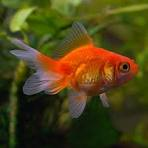

In [36]:
gold_fish = Image.open("../../data/gold_fish.jpg")
gold_fish

In [ ]:
gold_fish = Image.open("../../data/gold_fish.jpg").resize(IMAGE_SHAPE)
gold_fish_arr = np.array(gold_fish, dtype=np.float32)

# Scales [0, 255] -> [-1, 1] expected by keras.applications.MobileNetV2
# when the model was trained, they followed this range, which means we need to use that too
gold_fish_preprocessed = keras.applications.mobilenet_v2.preprocess_input(gold_fish_arr)
gold_fish_preprocessed.shape  # (224, 224, 3)

(224, 224, 3)

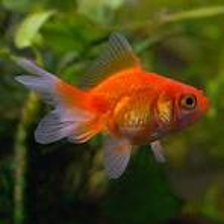

In [35]:
gold_fish = Image.open("../../data/gold_fish.jpg").resize(IMAGE_SHAPE)
gold_fish

In [22]:
result = classifier.predict(gold_fish_preprocessed[np.newaxis, ...])
print("Output shape:", result.shape)  # (1, 1000)

predicted_label_index = np.argmax(result)
print("Predicted index:", predicted_label_index)  # 1

# Built-in label decoder (returns top 3 predictions with class ID, name, and probability)
decoded = keras.applications.mobilenet_v2.decode_predictions(result, top=3)[0]
for class_id, label, score in decoded:
    print(f"{label}: {score:.2%}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 862ms/step
Output shape: (1, 1000)
Predicted index: 1
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
goldfish: 95.92%
tench: 0.08%
rock_beauty: 0.06%


In [24]:
import pathlib

data_dir = pathlib.Path(r'D:\deep_learning_course\data\datasets\flower_photos\flower_photos')
data_dir 

WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos')

In [25]:
list(data_dir.glob('*/*.jpg'))[:5]

[WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/daisy/100080576_f52e8ee070_n.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/daisy/10140303196_b88d3d6cec.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/daisy/10172379554_b296050f82_n.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/daisy/10172567486_2748826a8b.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/daisy/10172636503_21bededa75_n.jpg')]

In [26]:
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

3670


In [27]:
roses = list(data_dir.glob('roses/*'))
roses[:5]

[WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/10090824183_d02c613f10_m.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/102501987_3cdb8e5394_n.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/10503217854_e66a804309.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/10894627425_ec76bbc757_n.jpg'),
 WindowsPath('D:/deep_learning_course/data/datasets/flower_photos/flower_photos/roses/110472418_87b6a3aa98_m.jpg')]

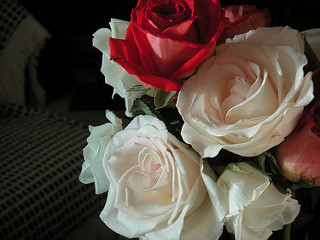

In [38]:
roses = list(data_dir.glob('roses/*'))
PIL.Image.open(str(roses[1]))

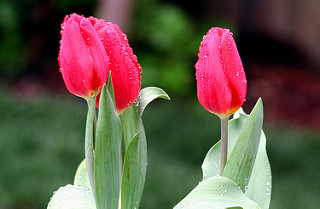

In [39]:
tulips = list(data_dir.glob('tulips/*'))
PIL.Image.open(str(tulips[0]))

In [40]:
flowers_images_dict = {
    'roses': list(data_dir.glob('roses/*')),
    'daisy': list(data_dir.glob('daisy/*')),
    'dandelion': list(data_dir.glob('dandelion/*')),
    'sunflowers': list(data_dir.glob('sunflowers/*')),
    'tulips': list(data_dir.glob('tulips/*')),
}

In [41]:
flowers_labels_dict = {
    'roses': 0,
    'daisy': 1,
    'dandelion': 2,
    'sunflowers': 3,
    'tulips': 4,
}

In [43]:
str(flowers_images_dict['roses'][0])

'D:\\deep_learning_course\\data\\datasets\\flower_photos\\flower_photos\\roses\\10090824183_d02c613f10_m.jpg'

In [44]:
mg = cv2.imread(str(flowers_images_dict['roses'][0]))

In [45]:
mg.shape

(240, 179, 3)

In [47]:
cv2.resize(mg,(224,224)).shape

(224, 224, 3)

In [49]:
X, y = [], []

for flower_name, images in flowers_images_dict.items():
    for image in images:
        img = cv2.imread(str(image))
        resized_img = cv2.resize(img,(224,224))
        X.append(resized_img)
        y.append(flowers_labels_dict[flower_name])

In [50]:
X = np.array(X)
y = np.array(y)

In [51]:

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

In [52]:
X_train_scaled = keras.applications.mobilenet_v2.preprocess_input(X_train.astype(np.float32))
X_test_scaled = keras.applications.mobilenet_v2.preprocess_input(X_test.astype(np.float32))

In [53]:
X[0].shape

(224, 224, 3)

In [54]:
IMAGE_SHAPE+(3,)

(224, 224, 3)

In [55]:
x0_resized = cv2.resize(X[0], IMAGE_SHAPE)
x1_resized = cv2.resize(X[1], IMAGE_SHAPE)
x2_resized = cv2.resize(X[2], IMAGE_SHAPE)

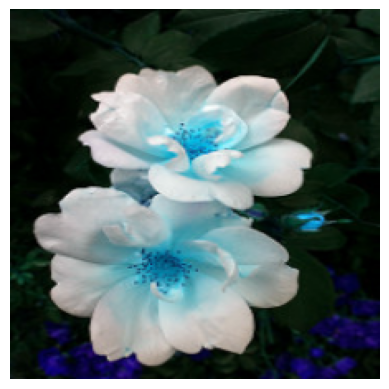

In [58]:
plt.axis('off')
plt.imshow(X[0])

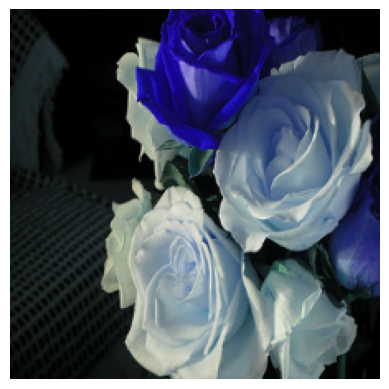

In [59]:
plt.axis('off')
plt.imshow(X[1])

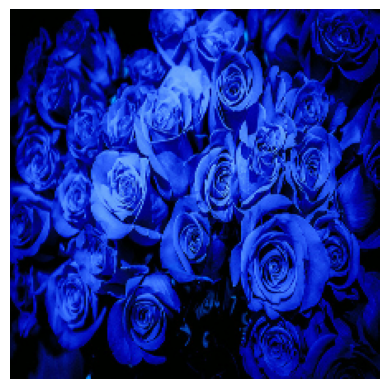

In [60]:
plt.axis('off')
plt.imshow(X[2])

In [61]:
predicted = classifier.predict(np.array([x0_resized, x1_resized, x2_resized]))
predicted = np.argmax(predicted, axis=1)
predicted

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 906ms/step


array([794, 721, 443])

Now take pre-trained model and retrain it using flowers images

In [63]:
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [64]:
num_classes = 5

model = Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(num_classes)
])

model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

model.summary()
model.fit(X_train_scaled, y_train, epochs=5)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5
86/86 ━━━━━━━━━━━━━━━━━━━━ 34s 354ms/step - accuracy: 0.7126 - loss: 0.7860
Epoch 2/5
86/86 ━━━━━━━━━━━━━━━━━━━━ 24s 274ms/step - accuracy: 0.8623 - loss: 0.4071
Epoch 3/5
86/86 ━━━━━━━━━━━━━━━━━━━━ 46s 542ms/step - accuracy: 0.8932 - loss: 0.3166
Epoch 4/5
86/86 ━━━━━━━━━━━━━━━━━━━━ 79s 914ms/step - accuracy: 0.9208 - loss: 0.2655
Epoch 5/5
86/86 ━━━━━━━━━━━━━━━━━━━━ 77s 886ms/step - accuracy: 0.9313 - loss: 0.2281


In [65]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print(f"Test Accuracy: {test_acc:.2%}")

# Predict on the first test image
predictions = model.predict(X_test_scaled[:5])
predicted_classes = np.argmax(predictions, axis=1)
print("Predicted:", predicted_classes)
print("Actual:   ", y_test[:5])

29/29 ━━━━━━━━━━━━━━━━━━━━ 10s 313ms/step - accuracy: 0.8682 - loss: 0.3711
Test Accuracy: 86.82%
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 764ms/step
Predicted: [1 1 2 4 2]
Actual:    [1 0 2 4 2]
